# # Exercise 1.1

## Classification of MNIST digits with a fully-connected neural network

In this exercise we will classify [MNIST digits](https://en.wikipedia.org/wiki/MNIST_database) using a fully-connected neural network

We start by importing the modules that we need

In [1]:
import numpy as np
from tqdm.notebook import tqdm
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.datasets as datasets
from torch.utils.data import DataLoader
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

We check that we have a GPU available

In [2]:
if torch.cuda.is_available():
    print("The code will run on GPU.")
else:
    print("The code will run on CPU. Go to Edit->Notebook Settings and choose GPU as the hardware accelerator")
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')  

The code will run on CPU. Go to Edit->Notebook Settings and choose GPU as the hardware accelerator


The MNIST dataset is a built-in dataset in PyTorch (it is a very common dataset to test algorithms on). 

We import it, and set our minibatch size

In [3]:
# set the number of pictures in a batch 
batch_size = 64
trainset = datasets.MNIST('./data', train=True, download=True, transform=transforms.ToTensor())

# shuffle: whether to shuffle the data or not in each epoch
# num_workers: how many subprocesses to use for data loading
train_loader = DataLoader(trainset, batch_size=batch_size, shuffle=True, num_workers=1)
testset = datasets.MNIST('./data', train=False, download=True, transform=transforms.ToTensor())
test_loader = DataLoader(testset, batch_size=batch_size, shuffle=False, num_workers=1)

First, we plot the images to get an idea of what data we're working with. MNIST images are $28\times28$ images of handwritten digits (0-9)

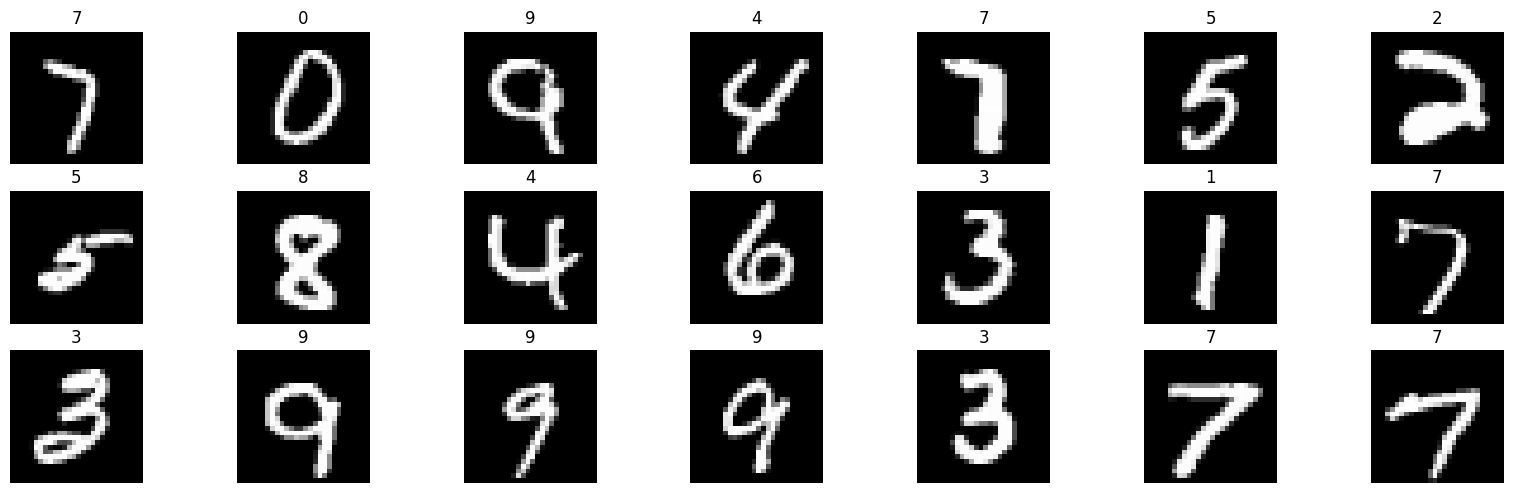

In [4]:
images, labels = next(iter(train_loader))
plt.figure(figsize=(20,10))

for i in range(21):
    plt.subplot(5,7,i+1)
    plt.imshow(images[i].numpy()[0], 'gray')
    plt.title(labels[i].item())
    plt.axis('off')

这段代码是在 **从训练集里拿一批图，然后画出来看看数据长什么样**。




1. `next(iter(train_loader))`  
   从训练 DataLoader 里取出 **一个 minibatch**（64 张图和对应标签）。

2. `plt.figure(figsize=(20,10))`  
   开一张比较大的画布。

3. `for i in range(21)`  
   只画这批里的 **前 21 张**。

4. `plt.subplot(5,7,i+1)`  
   排成 **5 行 × 7 列** 的格子。

5. `plt.imshow(images[i].numpy()[0], 'gray')`  
   显示第 `i` 张图。MNIST 张量形状是 `(1, 28, 28)`，`[0]` 去掉通道维，用灰度显示。

6. `plt.title(labels[i].item())`  
   标题是这张图的真实数字（0–9）。

7. `plt.axis('off')`  
   关掉坐标轴，只看图。

所以它不训练、不预测，只是 **可视化检查**：确认数据加载成功，并且数字和标签对得上。


这两行是：**从训练集拿出一批图，并开一张大画布准备画。**

---

`images, labels = next(iter(train_loader))`

拆成三步：

1. **`iter(train_loader)`**  
   把 DataLoader 变成迭代器。之后才能一次一次取批。

2. **`next(...)`**  
   只取 **第一批**，不等把 938 批都跑完。

3. **解包成 `images, labels`**  
   DataLoader 每批是一个元组 `(数据, 标签)`。

此时：

| 变量 | 形状 | 含义 |
|---|---|---|
| `images` | `(64, 1, 28, 28)` | 这一批 64 张灰度图，值在 `[0, 1]` |
| `labels` | `(64,)` | 对应的真实数字，例如 `7, 2, 1, …` |
images[0]          # 第 0 张图，形状 (1, 28, 28)
images[0, 0]       # 这张图的唯一通道，形状 (28, 28)
images[0, 0, 10, 15]  # 第 0 张、第 10 行、第 15 列，这才是「一个像素的值」

因为 `shuffle=True`，每次重新跑这个 cell，**第一批是哪 64 张会变**。

---

`plt.figure(figsize=(20, 10))`

matplotlib 新建一张图。

- `figsize=(宽, 高)`，单位是 **英寸**
- `(20, 10)`：很宽的画布，后面要并排画 21 张小图，太小会挤在一起

这一行 **还不画 MNIST**，只是定画布大小。真正画图是后面的 `subplot` + `imshow`。

---

和训练循环的差别（方便记）

```python
# 这里：只看一批，用来检查数据
images, labels = next(iter(train_loader))

# 训练：把每一批都走一遍
for data, target in train_loader:
    ...
```

`images` / `labels` 和训练里的 `data` / `target` 是同一种东西，只是变量名不同。

You should implement a fully-connected network to classify the digits. It should contain 1 hidden layer with 100 units. Don't forget the ReLU activation function after the hidden layer. 

In [5]:
# class Network(nn.Module):
#     def __init__(self):
#         super(Network, self).__init__()
#         self.fully_connected1 = nn.Sequential(
#             ...,xx
#             ...,
#             )
        
#         self.fully_connected2 = nn.Sequential(
#             nn.Linear(100,10),
#             nn.Softmax(dim = 1)
#             )

class Network(nn.Module):
    def __init__(self):
        super(Network, self).__init__()
        self.fully_connected1 = nn.Sequential(
            nn.Linear(28*28, 100),
            nn.ReLU(),
            )
        
        self.fully_connected2 = nn.Sequential(
            nn.Linear(100, 10),
            nn.Softmax(dim=1)
            )
        
    def forward(self, x):
        x = x.view(x.size(0), -1)   # (batch, 1, 28, 28) → (batch, 784)
        x = self.fully_connected1(x)  # 784 → 100，再 ReLU
        x = self.fully_connected2(x)  # 100 → 10 类概率
        return x
        

1. nn.Sequential 是什么
一个 按顺序的管道：放进去的模块会一个接一个执行

2. forward 里写 x = self.fully_connected1(x)，就等于先 Linear 再 ReLU。
不用 Sequential 也可以拆开两个 self.xxx，再在 forward 里连着调用，效果一样。Sequential 只是打包方便。

3. nn.Linear(in_features, out_features)

4. ReLU(x)=max(0,x)

    x>0：原样输出

    x≤0：变成 0
    
画出来是一条「负半轴贴地、正半轴 45 度往上」的折线。


We instantiate a copy of our network and transfer it to the GPU if it's available

In [6]:
model = Network()
model.to(device)
#Initialize the optimer
optimizer = torch.optim.SGD(model.parameters(), lr=0.1)

We train the network for five epochs

```
num_epochs = 5
对每个 epoch:
    用 train_loader 更新模型，顺手数训练集对了几张
    用 test_loader 只预测，数测试集对了几张
    打印 train / test 准确率

```


In [7]:
num_epochs = 5

for epoch in tqdm(range(num_epochs), unit='epoch'):  # tqdm是进度条
    #For each epoch
    train_correct = 0    # 训练集对了几张, 每轮都要初始化
    for minibatch_no, (data, target) in tqdm(enumerate(train_loader), total=len(train_loader)):
        data, target = data.to(device), target.to(device)
        #Zero the gradients computed for each weight
        optimizer.zero_grad()

        #Forward pass your image through the network
        output = model(data)

        #Compute the loss
        loss = F.nll_loss(torch.log(output), target)

        #Backward pass through the network
        loss.backward()

        #Update the weights
        optimizer.step()
        
        #Compute how many were correctly classified
        predicted = output.argmax(1)
        train_correct += (target==predicted).sum().cpu().item()
        
    #Comput the test accuracy
    test_correct = 0
    for data, target in test_loader:
        data = data.to(device)
        with torch.no_grad():
            output = model(data)
        predicted = output.argmax(1).cpu()
        test_correct += (target==predicted).sum().item()
    train_acc = train_correct/len(trainset)
    test_acc = test_correct/len(testset)
    print("Accuracy train: {train:.1f}%\t test: {test:.1f}%".format(test=100*test_acc, train=100*train_acc))

  0%|          | 0/5 [00:00<?, ?epoch/s]

  0%|          | 0/938 [00:00<?, ?it/s]

Accuracy train: 87.9%	 test: 92.3%


  0%|          | 0/938 [00:00<?, ?it/s]

Accuracy train: 93.3%	 test: 92.8%


  0%|          | 0/938 [00:00<?, ?it/s]

Accuracy train: 94.9%	 test: 95.4%


  0%|          | 0/938 [00:00<?, ?it/s]

Accuracy train: 95.9%	 test: 95.7%


  0%|          | 0/938 [00:00<?, ?it/s]

Accuracy train: 96.5%	 test: 96.4%


You should now have a model that has about 96% accuracy on the test set.
Try to get an even better accuracy. You can
* Change the number of hidden layers
* Change the number of units in the hidden layers
* Try changing the learning rate by factors of 10. What happens if it is too high or too low?
* Try using sigmoid instead of ReLU activation. What happens?

How large accuracy can you get?

Try showing the classification output (probabilities) from the model alongside the ground truth.

* Which are classified correctly/incorrectly? 
* If it's incorrect, what is the second most likely class?
* Do the misclassifications you see make sense? Why/why not?

In [8]:
# Better model: 2 hidden layers (256 units) + ReLU, slightly lower lr
class NetworkBetter(nn.Module):
    def __init__(self):
        super(NetworkBetter, self).__init__()
        self.fc = nn.Sequential(
            nn.Linear(28 * 28, 256),
            nn.ReLU(),
            nn.Linear(256, 256),
            nn.ReLU(),
            nn.Linear(256, 10),
            nn.Softmax(dim=1),
        )

    def forward(self, x):
        x = x.view(x.size(0), -1)
        return self.fc(x)

In [9]:
model = NetworkBetter()
model.to(device)
#Initialize the optimer
optimizer = torch.optim.SGD(model.parameters(), lr=0.1666)

In [12]:
num_epochs = 7
for epoch in tqdm(range(num_epochs), unit='epoch'):
    train_correct = 0
    for data, target in train_loader:
        data, target = data.to(device), target.to(device)
        optimizer.zero_grad()
        output = model(data)
        loss = F.nll_loss(torch.log(output), target)
        loss.backward()
        optimizer.step()
        train_correct += (target == output.argmax(1)).sum().cpu().item()

    test_correct = 0
    for data, target in test_loader:
        data = data.to(device)
        with torch.no_grad():
            output = model(data)
        test_correct += (target == output.argmax(1).cpu()).sum().item()

    print("Accuracy train: {train:.1f}%\t test: {test:.1f}%".format(
        train=100 * train_correct / len(trainset),
        test=100 * test_correct / len(testset),
    ))



  0%|          | 0/7 [00:00<?, ?epoch/s]

Accuracy train: 86.6%	 test: 93.6%
Accuracy train: 94.6%	 test: 93.2%
Accuracy train: 96.4%	 test: 96.3%
Accuracy train: 97.3%	 test: 97.2%
Accuracy train: 97.9%	 test: 97.5%
Accuracy train: 98.3%	 test: 97.5%
Accuracy train: 98.6%	 test: 97.8%


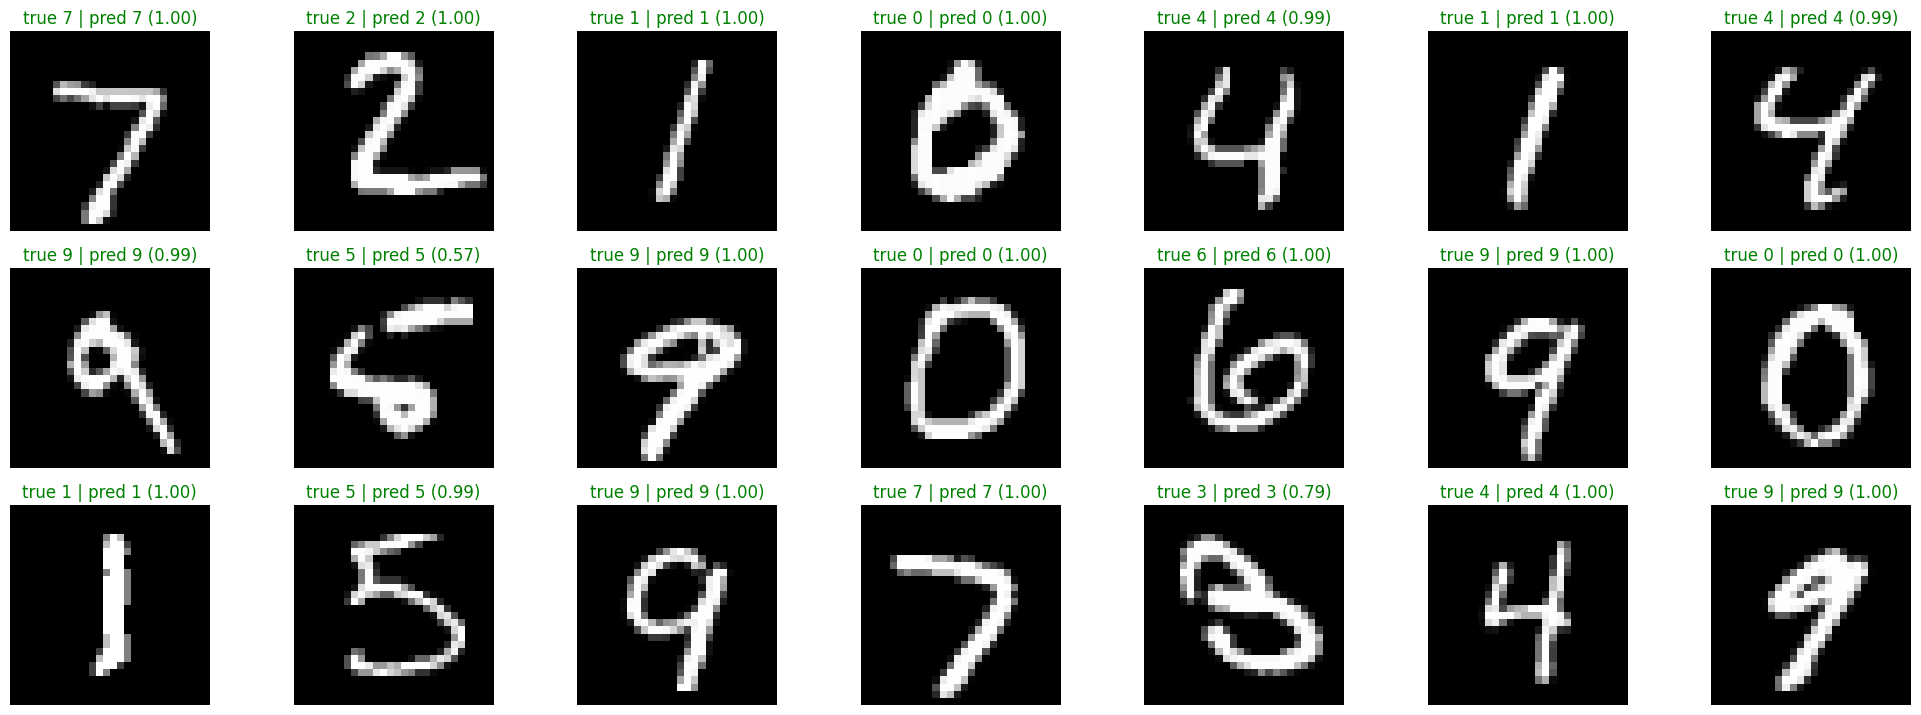

In [13]:
# Show predictions vs ground truth
images, labels = next(iter(test_loader))
with torch.no_grad():
    probs = model(images.to(device)).cpu()

pred = probs.argmax(1)
second = probs.topk(2, dim=1).indices[:, 1]

plt.figure(figsize=(20, 12))
for i in range(21):
    plt.subplot(5, 7, i + 1)
    plt.imshow(images[i].numpy()[0], 'gray')
    true = labels[i].item()
    p = pred[i].item()
    conf = probs[i, p].item()
    ok = (p == true)
    title = f"true {true} | pred {p} ({conf:.2f})"
    if not ok:
        title += f"\n2nd {second[i].item()} ({probs[i, second[i]].item():.2f})"
    plt.title(title, color='green' if ok else 'red')
    plt.axis('off')
plt.tight_layout()